# Multimodal Medical Summarization — Replacement Notebook

**Project goal:** generate an English medical summary from a code-mixed medical question and its associated medical image.

This notebook is organized into 7 sections:

1. Environment and configuration
2. Dataset loading and validation
3. Leakage-safe image-level train/validation/test split
4. Text-only BART baseline
5. Vision Transformer (ViT) image encoder
6. Multimodal ViT + BART model
7. Training, generation and evaluation

**Important:** This is an academic summarization prototype, not a diagnostic system. Generated text must be reviewed by a qualified human before any clinical use.


## Section 1 — Environment, imports and configuration

In [5]:
# If needed, run this once in a notebook cell:
# %pip install -U torch torchvision transformers accelerate evaluate rouge_score pandas pyarrow scikit-learn pillow matplotlib tqdm

import os
import sys
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

from transformers import (
    AutoTokenizer,
    BartForConditionalGeneration,
    ViTImageProcessor,
    ViTModel,
)
from transformers.modeling_outputs import BaseModelOutput

warnings.filterwarnings("ignore")

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# -----------------------------
# Project configuration
# -----------------------------
TEXT_COLUMN = "Codemixed_Question"
TARGET_COLUMN = "summary"
IMAGE_COLUMN = "Image_path"

BART_NAME = "facebook/bart-base"
VIT_NAME = "google/vit-base-patch16-224-in21k"

MAX_SOURCE_LENGTH = 256
MAX_TARGET_LENGTH = 128
IMAGE_SIZE = 224

# RTX 3050 6GB: start conservatively.
BATCH_SIZE = 1
GRAD_ACCUM_STEPS = 4
NUM_EPOCHS = 3
LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.01

# Freeze ViT initially to reduce memory and training time.
FREEZE_VIT = True

OUTPUT_DIR = Path("outputs_multimodal")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration loaded.")


/home/amitabha-ghsoh/Documents/Images_dataset/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.14.4 (main, Aug 20 2026, 10:41:58) [GCC 15.2.0]
PyTorch: 2.14.0+cu130
Device: cpu
Configuration loaded.


## Section 2 — Load and validate the dataset

In [6]:
from pathlib import Path

def find_parquet_file():
    candidates = [
        Path("train-00000-of-00001-d99c2c6aef2fc2d4.parquet"),
        Path("data/train-00000-of-00001-d99c2c6aef2fc2d4.parquet"),
        Path.home() / "Downloads/train-00000-of-00001-d99c2c6aef2fc2d4.parquet",
    ]
    for p in candidates:
        if p.exists():
            return p

    # Search Downloads for any parquet as a fallback.
    downloads = Path.home() / "Downloads"
    if downloads.exists():
        files = sorted(downloads.glob("*.parquet"))
        if files:
            return files[0]

    raise FileNotFoundError(
        "Parquet file not found. Put the dataset parquet file in the notebook folder "
        "or in ~/Downloads, then run this cell again."
    )

parquet_path = find_parquet_file()
df = pd.read_parquet(parquet_path)

print("Dataset:", parquet_path)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

required = {TEXT_COLUMN, TARGET_COLUMN, IMAGE_COLUMN}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Basic cleaning
df = df[[TEXT_COLUMN, TARGET_COLUMN, IMAGE_COLUMN]].copy()
df = df.dropna(subset=[TEXT_COLUMN, TARGET_COLUMN, IMAGE_COLUMN]).reset_index(drop=True)

for col in [TEXT_COLUMN, TARGET_COLUMN, IMAGE_COLUMN]:
    df[col] = df[col].astype(str).str.strip()

df = df[
    (df[TEXT_COLUMN] != "") &
    (df[TARGET_COLUMN] != "") &
    (df[IMAGE_COLUMN] != "")
].reset_index(drop=True)

print("After cleaning:", df.shape)
print("Unique images:", df[IMAGE_COLUMN].nunique())
print("Unique questions:", df[TEXT_COLUMN].nunique())
print("Unique summaries:", df[TARGET_COLUMN].nunique())

display(df.head(3))


Dataset: /home/amitabha-ghsoh/Downloads/train-00000-of-00001-d99c2c6aef2fc2d4.parquet
Shape: (3015, 3)
Columns: ['Codemixed_Question', 'summary', 'Image_path']
After cleaning: (3015, 3)
Unique images: 372
Unique questions: 3015
Unique summaries: 3015


,Codemixed_Question,summary,Image_path
0,Meri 11 saal ki beti ko 13 din pehle MRSA+ dia...,"What could be the cause of high fever, swollen...",Multimodal_images/swollen tonsils/Image_2.jpg
1,"Namaste, Mere 7 saal ke bete ke tonsils bohot ...",Should a parent worry about a 7-year-old with ...,Multimodal_images/swollen tonsils/Image_2.jpg
2,Mere 3 1/2 saal ke bacche ke khoon laal ho gay...,What other potential causes should be consider...,Multimodal_images/swollen tonsils/Image_9.jpg


In [7]:
# ---------------------------------------------------------
# Locate the image root automatically.
# Image_path values look like:
# Multimodal_images/swollen tonsils/Image_2.jpg
# ---------------------------------------------------------

sample_rel = Path(df[IMAGE_COLUMN].iloc[0])

candidate_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path.home(),
    Path.home() / "Documents" / "Images_dataset",
    Path.home() / "Downloads",
]

def locate_image_root(relative_path):
    for root in candidate_roots:
        candidate = root / relative_path
        if candidate.is_file():
            return root
    return None

IMAGE_ROOT = locate_image_root(sample_rel)

if IMAGE_ROOT is None:
    print("Could not automatically locate the image root.")
    print("Current directory:", Path.cwd())
    print("Example relative image:", sample_rel)
    print("\nSet IMAGE_ROOT manually, for example:")
    print('IMAGE_ROOT = Path("/your/path/to/Images_dataset")')
else:
    print("Detected IMAGE_ROOT:", IMAGE_ROOT)

def resolve_image_path(relative_path):
    p = Path(relative_path)
    if p.is_absolute() and p.is_file():
        return p
    if IMAGE_ROOT is not None:
        return IMAGE_ROOT / p
    return p

df["Image_path_full"] = df[IMAGE_COLUMN].apply(resolve_image_path)

df["image_exists"] = df["Image_path_full"].apply(lambda p: Path(p).is_file())

print("Images found:", int(df["image_exists"].sum()), "/", len(df))

missing_images = df.loc[~df["image_exists"], IMAGE_COLUMN].head(10).tolist()
if missing_images:
    print("First missing image paths:")
    for p in missing_images:
        print(" -", p)

if df["image_exists"].sum() == 0:
    raise FileNotFoundError(
        "No images were found. Set IMAGE_ROOT manually before continuing."
    )

# For a clean experiment, remove records whose image file is unavailable.
df = df[df["image_exists"]].drop(columns=["image_exists"]).reset_index(drop=True)

print("Usable records:", len(df))
print("Usable unique images:", df[IMAGE_COLUMN].nunique())


Detected IMAGE_ROOT: /home/amitabha-ghsoh/Documents/Images_dataset
Images found: 3015 / 3015
Usable records: 3015
Usable unique images: 372


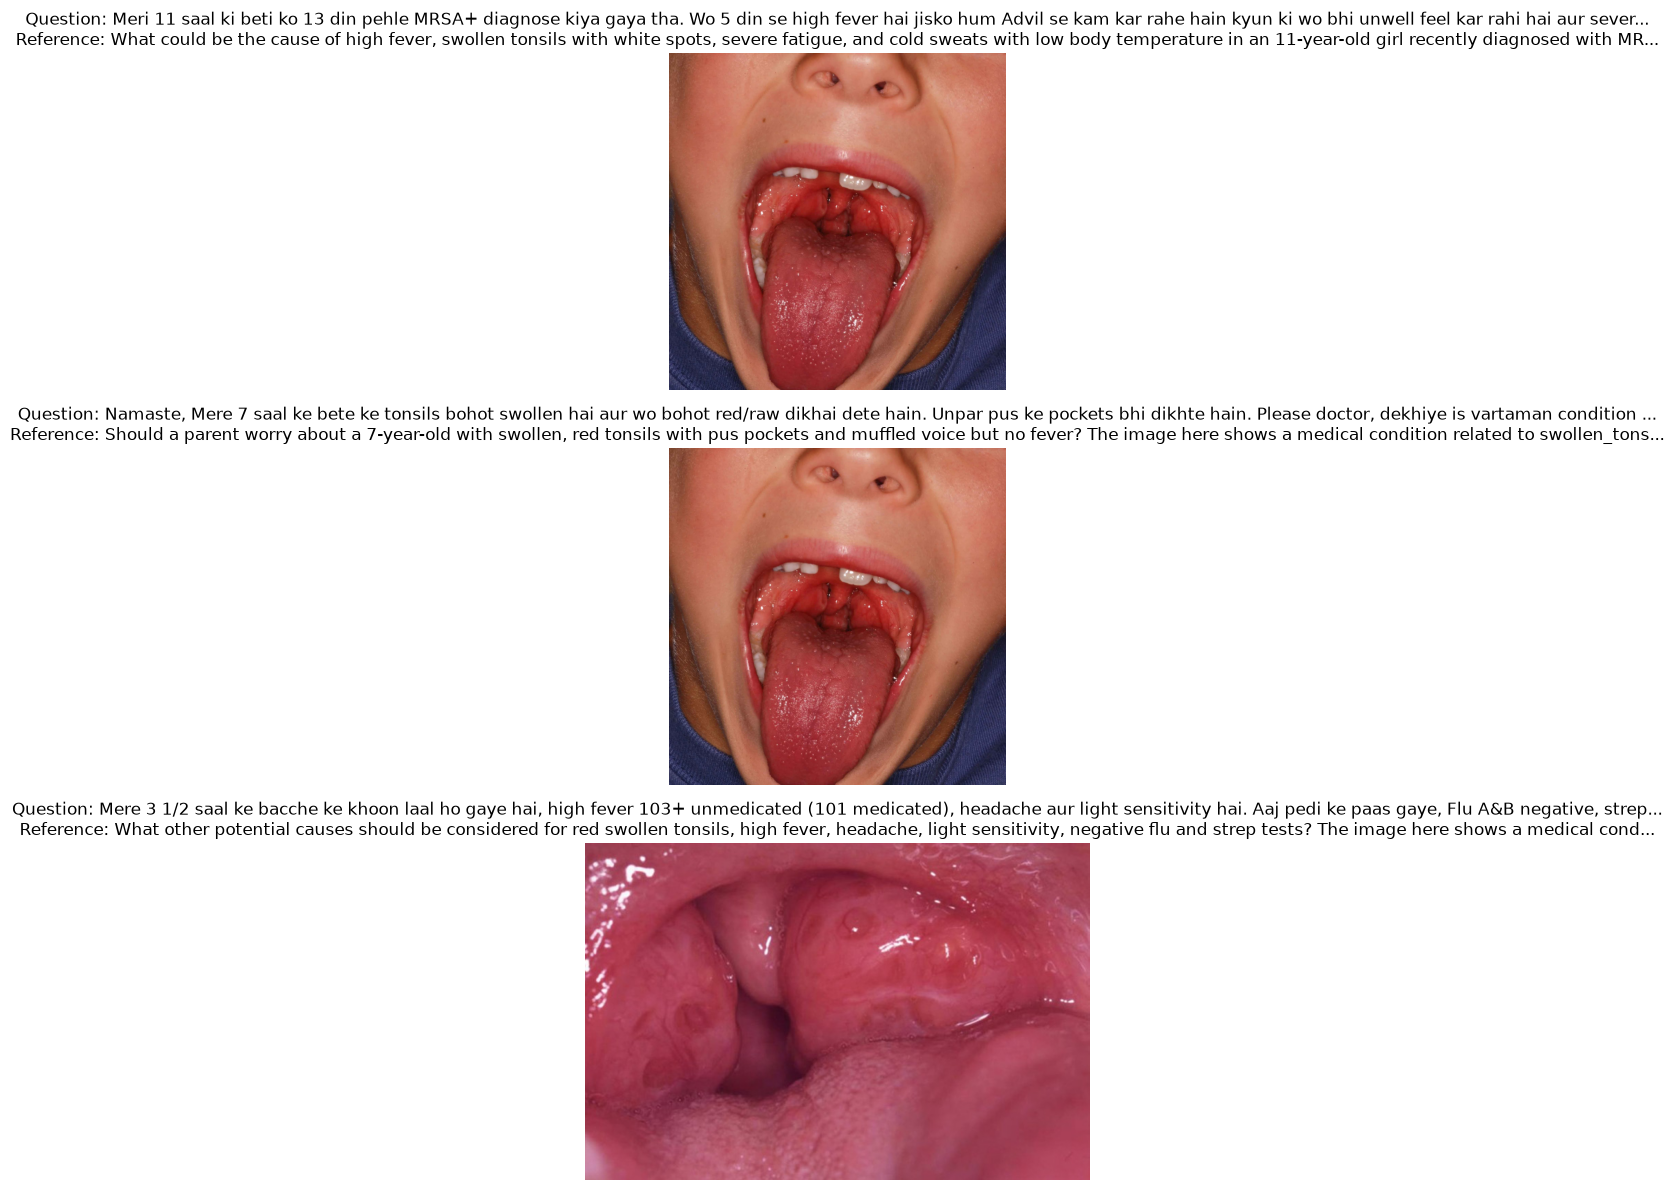

In [8]:
# Visual sanity check
import matplotlib.pyplot as plt

n = min(3, len(df))
fig, axes = plt.subplots(n, 1, figsize=(10, 4*n))
if n == 1:
    axes = [axes]

for ax, (_, row) in zip(axes, df.head(n).iterrows()):
    image = Image.open(row["Image_path_full"]).convert("RGB")
    ax.imshow(image)
    ax.axis("off")
    ax.set_title(
        f"Question: {row[TEXT_COLUMN][:180]}...\n"
        f"Reference: {row[TARGET_COLUMN][:180]}..."
    )

plt.tight_layout()
plt.show()


## Section 3 — Leakage-safe image-level splitting

In [9]:
# IMPORTANT:
# The same image can have multiple questions/records.
# Therefore split UNIQUE IMAGES first, then assign all rows belonging to
# each image to the same split.

unique_images = np.array(sorted(df[IMAGE_COLUMN].unique()))

train_images, temp_images = train_test_split(
    unique_images,
    test_size=0.20,
    random_state=SEED
)

val_images, test_images = train_test_split(
    temp_images,
    test_size=0.50,
    random_state=SEED
)

train_set = set(train_images)
val_set = set(val_images)
test_set = set(test_images)

assert train_set.isdisjoint(val_set)
assert train_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)

df["split"] = df[IMAGE_COLUMN].map(
    lambda x: "train" if x in train_set else ("validation" if x in val_set else "test")
)

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "validation"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print("Unique image split:")
print(" Train:", len(train_images))
print(" Validation:", len(val_images))
print(" Test:", len(test_images))

print("\nRecord split:")
print(" Train:", len(train_df))
print(" Validation:", len(val_df))
print(" Test:", len(test_df))

# Final leakage checks
assert set(train_df[IMAGE_COLUMN]).isdisjoint(set(val_df[IMAGE_COLUMN]))
assert set(train_df[IMAGE_COLUMN]).isdisjoint(set(test_df[IMAGE_COLUMN]))
assert set(val_df[IMAGE_COLUMN]).isdisjoint(set(test_df[IMAGE_COLUMN]))

print("\n✓ No image leakage between splits.")


Unique image split:
 Train: 297
 Validation: 37
 Test: 38

Record split:
 Train: 2562
 Validation: 280
 Test: 173

✓ No image leakage between splits.


In [10]:
# Save the exact split so future experiments use the same test set.
split_file = OUTPUT_DIR / "dataset_split.csv"
df[[TEXT_COLUMN, TARGET_COLUMN, IMAGE_COLUMN, "split"]].to_csv(split_file, index=False)

print("Saved split:", split_file)
print("\nRecords per image:")
print(df.groupby(IMAGE_COLUMN).size().describe())


Saved split: outputs_multimodal/dataset_split.csv

Records per image:
count    372.000000
mean       8.104839
std       36.016427
min        1.000000
25%        1.000000
50%        3.000000
75%        8.000000
max      673.000000
dtype: float64


## Section 4 — Text-only BART baseline

In [11]:
from torch.utils.data import Dataset, DataLoader

tokenizer = AutoTokenizer.from_pretrained(BART_NAME)

class TextSummaryDataset(Dataset):
    def __init__(self, frame, tokenizer):
        self.frame = frame.reset_index(drop=True)
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]

        source = self.tokenizer(
            row[TEXT_COLUMN],
            max_length=MAX_SOURCE_LENGTH,
            truncation=True,
            padding="max_length",
            return_tensors="pt",
        )

        target = self.tokenizer(
            row[TARGET_COLUMN],
            max_length=MAX_TARGET_LENGTH,
            truncation=True,
            padding="max_length",
            return_tensors="pt",
        )

        labels = target["input_ids"].squeeze(0)
        labels[labels == tokenizer.pad_token_id] = -100

        return {
            "input_ids": source["input_ids"].squeeze(0),
            "attention_mask": source["attention_mask"].squeeze(0),
            "labels": labels,
        }

train_text_ds = TextSummaryDataset(train_df, tokenizer)
val_text_ds = TextSummaryDataset(val_df, tokenizer)
test_text_ds = TextSummaryDataset(test_df, tokenizer)

train_loader = DataLoader(train_text_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_text_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_text_ds, batch_size=BATCH_SIZE, shuffle=False)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Train batches: 2562
Validation batches: 280
Test batches: 173


In [12]:
bart_baseline = BartForConditionalGeneration.from_pretrained(BART_NAME)
bart_baseline.to(DEVICE)

# Gradient checkpointing reduces memory usage on smaller GPUs.
if hasattr(bart_baseline, "gradient_checkpointing_enable"):
    bart_baseline.gradient_checkpointing_enable()

optimizer = torch.optim.AdamW(
    bart_baseline.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0

    if training:
        optimizer.zero_grad(set_to_none=True)

    for step, batch in enumerate(tqdm(loader, leave=False)):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):
            outputs = model(**batch)
            loss = outputs.loss / (GRAD_ACCUM_STEPS if training else 1)

        if training:
            scaler.scale(loss).backward()

            if (step + 1) % GRAD_ACCUM_STEPS == 0 or (step + 1) == len(loader):
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item() * (GRAD_ACCUM_STEPS if training else 1)

    return total_loss / max(len(loader), 1)

best_val_loss = float("inf")

for epoch in range(NUM_EPOCHS):
    train_loss = run_epoch(bart_baseline, train_loader, optimizer)

    with torch.no_grad():
        val_loss = run_epoch(bart_baseline, val_loader)

    print(
        f"Epoch {epoch+1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        bart_baseline.save_pretrained(OUTPUT_DIR / "bart_baseline")
        tokenizer.save_pretrained(OUTPUT_DIR / "bart_baseline")
        print("  ✓ Saved best BART baseline")


  0%|          | 0/2562 [00:00<?, ?it/s][transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


KeyboardInterrupt: 

In [ ]:
# ROUGE evaluation for the text-only baseline
import evaluate

rouge = evaluate.load("rouge")

best_bart = BartForConditionalGeneration.from_pretrained(
    OUTPUT_DIR / "bart_baseline"
).to(DEVICE)

best_bart.eval()

predictions = []
references = []

for batch_idx, batch in enumerate(tqdm(test_loader)):
    input_ids = batch["input_ids"].to(DEVICE)
    attention_mask = batch["attention_mask"].to(DEVICE)

    with torch.no_grad():
        generated = best_bart.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            max_new_tokens=MAX_TARGET_LENGTH,
            num_beams=4,
            early_stopping=True,
        )

    predictions.extend(
        tokenizer.batch_decode(generated, skip_special_tokens=True)
    )

    labels = batch["labels"].clone()
    labels[labels == -100] = tokenizer.pad_token_id

    references.extend(
        tokenizer.batch_decode(labels, skip_special_tokens=True)
    )

baseline_scores = rouge.compute(
    predictions=predictions,
    references=references,
    use_stemmer=True
)

print("BART baseline:")
for k, v in baseline_scores.items():
    print(f"{k}: {v:.4f}")

pd.DataFrame({
    "prediction": predictions,
    "reference": references,
}).to_csv(OUTPUT_DIR / "bart_baseline_predictions.csv", index=False)


## Section 5 — Vision Transformer (ViT) image encoder

In [ ]:
image_processor = ViTImageProcessor.from_pretrained(VIT_NAME)
vit = ViTModel.from_pretrained(VIT_NAME)

if FREEZE_VIT:
    for param in vit.parameters():
        param.requires_grad = False

vit.to(DEVICE)
vit.eval() if FREEZE_VIT else vit.train()

print("ViT hidden size:", vit.config.hidden_size)
print("ViT image size:", vit.config.image_size)
print("ViT patch size:", vit.config.patch_size)


In [ ]:
# Test ViT on one image
sample_image = Image.open(train_df["Image_path_full"].iloc[0]).convert("RGB")
pixel_values = image_processor(
    images=sample_image,
    return_tensors="pt"
)["pixel_values"].to(DEVICE)

with torch.no_grad():
    vit_output = vit(pixel_values=pixel_values)

print("pixel_values:", tuple(pixel_values.shape))
print("ViT last_hidden_state:", tuple(vit_output.last_hidden_state.shape))
print("CLS embedding:", tuple(vit_output.last_hidden_state[:, 0].shape))


## Section 6 — Multimodal ViT + BART model

In [ ]:
class MultimodalMedicalDataset(Dataset):
    def __init__(
        self,
        frame,
        tokenizer,
        image_processor,
        max_source_length=256,
        max_target_length=128,
    ):
        self.frame = frame.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.image_processor = image_processor
        self.max_source_length = max_source_length
        self.max_target_length = max_target_length

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]

        text_inputs = self.tokenizer(
            row[TEXT_COLUMN],
            max_length=self.max_source_length,
            truncation=True,
            padding="max_length",
            return_tensors="pt",
        )

        target_inputs = self.tokenizer(
            row[TARGET_COLUMN],
            max_length=self.max_target_length,
            truncation=True,
            padding="max_length",
            return_tensors="pt",
        )

        image = Image.open(row["Image_path_full"]).convert("RGB")
        image_inputs = self.image_processor(
            images=image,
            return_tensors="pt",
        )

        labels = target_inputs["input_ids"].squeeze(0)
        labels[labels == self.tokenizer.pad_token_id] = -100

        return {
            "input_ids": text_inputs["input_ids"].squeeze(0),
            "attention_mask": text_inputs["attention_mask"].squeeze(0),
            "pixel_values": image_inputs["pixel_values"].squeeze(0),
            "labels": labels,
        }

train_mm_ds = MultimodalMedicalDataset(
    train_df, tokenizer, image_processor,
    MAX_SOURCE_LENGTH, MAX_TARGET_LENGTH
)
val_mm_ds = MultimodalMedicalDataset(
    val_df, tokenizer, image_processor,
    MAX_SOURCE_LENGTH, MAX_TARGET_LENGTH
)
test_mm_ds = MultimodalMedicalDataset(
    test_df, tokenizer, image_processor,
    MAX_SOURCE_LENGTH, MAX_TARGET_LENGTH
)

train_mm_loader = DataLoader(train_mm_ds, batch_size=BATCH_SIZE, shuffle=True)
val_mm_loader = DataLoader(val_mm_ds, batch_size=BATCH_SIZE, shuffle=False)
test_mm_loader = DataLoader(test_mm_ds, batch_size=BATCH_SIZE, shuffle=False)

batch = next(iter(train_mm_loader))
print({k: tuple(v.shape) for k, v in batch.items()})


In [ ]:
class ViTBartMultimodal(nn.Module):
    """
    Multimodal encoder-decoder:
      text -> BART encoder
      image -> ViT
      ViT features -> projection
      text + image tokens -> concatenated encoder sequence
      fused sequence -> BART decoder
    """

    def __init__(
        self,
        bart_name=BART_NAME,
        vit_name=VIT_NAME,
        freeze_vit=True,
    ):
        super().__init__()

        self.bart = BartForConditionalGeneration.from_pretrained(bart_name)
        self.vit = ViTModel.from_pretrained(vit_name)

        bart_hidden = self.bart.config.d_model
        vit_hidden = self.vit.config.hidden_size

        self.image_projection = nn.Sequential(
            nn.Linear(vit_hidden, bart_hidden),
            nn.LayerNorm(bart_hidden),
            nn.GELU(),
            nn.Dropout(0.1),
        )

        self.fusion_layer = nn.Sequential(
            nn.Linear(bart_hidden, bart_hidden),
            nn.LayerNorm(bart_hidden),
            nn.GELU(),
            nn.Dropout(0.1),
        )

        self.freeze_vit = freeze_vit

        if freeze_vit:
            for p in self.vit.parameters():
                p.requires_grad = False

        if hasattr(self.bart, "gradient_checkpointing_enable"):
            self.bart.gradient_checkpointing_enable()

    def encode_multimodal(
        self,
        input_ids,
        attention_mask,
        pixel_values,
    ):
        # Text branch
        text_encoder_outputs = self.bart.model.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
            return_dict=True,
        )
        text_features = text_encoder_outputs.last_hidden_state

        # Image branch
        if self.freeze_vit:
            with torch.no_grad():
                image_outputs = self.vit(
                    pixel_values=pixel_values,
                    return_dict=True,
                )
        else:
            image_outputs = self.vit(
                pixel_values=pixel_values,
                return_dict=True,
            )

        # Use all ViT patch tokens, not only CLS.
        image_features = self.image_projection(
            image_outputs.last_hidden_state
        )

        # Light fusion transformation.
        image_features = self.fusion_layer(image_features)

        # Concatenate text tokens and image tokens.
        fused_features = torch.cat(
            [text_features, image_features],
            dim=1,
        )

        image_attention = torch.ones(
            image_features.size(0),
            image_features.size(1),
            dtype=attention_mask.dtype,
            device=attention_mask.device,
        )

        fused_attention_mask = torch.cat(
            [attention_mask, image_attention],
            dim=1,
        )

        return fused_features, fused_attention_mask

    def forward(
        self,
        input_ids,
        attention_mask,
        pixel_values,
        labels=None,
    ):
        fused_features, fused_attention_mask = self.encode_multimodal(
            input_ids=input_ids,
            attention_mask=attention_mask,
            pixel_values=pixel_values,
        )

        encoder_outputs = BaseModelOutput(
            last_hidden_state=fused_features
        )

        return self.bart(
            input_ids=None,
            attention_mask=fused_attention_mask,
            encoder_outputs=encoder_outputs,
            labels=labels,
            return_dict=True,
        )

    @torch.no_grad()
    def generate_summary(
        self,
        input_ids,
        attention_mask,
        pixel_values,
        **generation_kwargs,
    ):
        fused_features, fused_attention_mask = self.encode_multimodal(
            input_ids=input_ids,
            attention_mask=attention_mask,
            pixel_values=pixel_values,
        )

        encoder_outputs = BaseModelOutput(
            last_hidden_state=fused_features
        )

        return self.bart.generate(
            input_ids=input_ids,
            attention_mask=fused_attention_mask,
            encoder_outputs=encoder_outputs,
            **generation_kwargs,
        )

model = ViTBartMultimodal(
    bart_name=BART_NAME,
    vit_name=VIT_NAME,
    freeze_vit=FREEZE_VIT,
).to(DEVICE)

print("Multimodal model created.")
print("BART hidden size:", model.bart.config.d_model)
print("ViT hidden size:", model.vit.config.hidden_size)


In [ ]:
# Quick forward-pass test before starting a long training run.
model.train()

test_batch = next(iter(train_mm_loader))
test_batch = {k: v.to(DEVICE) for k, v in test_batch.items()}

with torch.amp.autocast(
    device_type="cuda",
    enabled=torch.cuda.is_available()
):
    test_outputs = model(**test_batch)

print("Forward pass successful.")
print("Loss:", float(test_outputs.loss.detach().cpu()))


In [ ]:
# Train the multimodal model
mm_optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

mm_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

def run_mm_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    if FREEZE_VIT:
        model.vit.eval()

    total_loss = 0.0

    if training:
        optimizer.zero_grad(set_to_none=True)

    for step, batch in enumerate(tqdm(loader, leave=False)):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):
            outputs = model(**batch)
            loss = outputs.loss / (GRAD_ACCUM_STEPS if training else 1)

        if training:
            mm_scaler.scale(loss).backward()

            if (step + 1) % GRAD_ACCUM_STEPS == 0 or (step + 1) == len(loader):
                mm_scaler.step(optimizer)
                mm_scaler.update()
                optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item() * (GRAD_ACCUM_STEPS if training else 1)

    return total_loss / max(len(loader), 1)

best_mm_val = float("inf")
best_mm_path = OUTPUT_DIR / "vit_bart_multimodal"

for epoch in range(NUM_EPOCHS):
    train_loss = run_mm_epoch(model, train_mm_loader, mm_optimizer)

    with torch.no_grad():
        val_loss = run_mm_epoch(model, val_mm_loader)

    print(
        f"Epoch {epoch+1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_mm_val:
        best_mm_val = val_loss
        best_mm_path.mkdir(parents=True, exist_ok=True)
        torch.save(
            model.state_dict(),
            best_mm_path / "model.pt"
        )
        tokenizer.save_pretrained(best_mm_path)
        image_processor.save_pretrained(best_mm_path)
        print("  ✓ Saved best multimodal checkpoint")


## Section 7 — Test generation, ROUGE evaluation and qualitative comparison

In [ ]:
# Reload best multimodal checkpoint
best_model = ViTBartMultimodal(
    bart_name=BART_NAME,
    vit_name=VIT_NAME,
    freeze_vit=FREEZE_VIT,
).to(DEVICE)

best_model.load_state_dict(
    torch.load(
        OUTPUT_DIR / "vit_bart_multimodal" / "model.pt",
        map_location=DEVICE
    )
)
best_model.eval()

mm_predictions = []
mm_references = []
mm_questions = []
mm_images = []

for batch_idx, batch in enumerate(tqdm(test_mm_loader)):
    input_ids = batch["input_ids"].to(DEVICE)
    attention_mask = batch["attention_mask"].to(DEVICE)
    pixel_values = batch["pixel_values"].to(DEVICE)

    generated = best_model.generate_summary(
        input_ids=input_ids,
        attention_mask=attention_mask,
        pixel_values=pixel_values,
        max_new_tokens=MAX_TARGET_LENGTH,
        num_beams=4,
        early_stopping=True,
        no_repeat_ngram_size=3,
    )

    mm_predictions.extend(
        tokenizer.batch_decode(
            generated,
            skip_special_tokens=True
        )
    )

    labels = batch["labels"].clone()
    labels[labels == -100] = tokenizer.pad_token_id

    mm_references.extend(
        tokenizer.batch_decode(
            labels,
            skip_special_tokens=True
        )
    )

# Preserve row-level metadata in the same test order.
test_meta = test_df.reset_index(drop=True)

results_df = pd.DataFrame({
    "question": test_meta[TEXT_COLUMN].tolist(),
    "image_path": test_meta[IMAGE_COLUMN].tolist(),
    "reference": mm_references,
    "prediction": mm_predictions,
})

mm_scores = rouge.compute(
    predictions=mm_predictions,
    references=mm_references,
    use_stemmer=True,
)

print("Multimodal ViT + BART:")
for k, v in mm_scores.items():
    print(f"{k}: {v:.4f}")

results_df.to_csv(
    OUTPUT_DIR / "vit_bart_multimodal_predictions.csv",
    index=False
)


In [ ]:
# Compare baseline and multimodal metrics.
comparison = pd.DataFrame([
    {
        "model": "BART text-only baseline",
        "input": "Text",
        "rouge1": baseline_scores.get("rouge1", np.nan),
        "rouge2": baseline_scores.get("rouge2", np.nan),
        "rougeL": baseline_scores.get("rougeL", np.nan),
    },
    {
        "model": "ViT + BART multimodal",
        "input": "Text + Image",
        "rouge1": mm_scores.get("rouge1", np.nan),
        "rouge2": mm_scores.get("rouge2", np.nan),
        "rougeL": mm_scores.get("rougeL", np.nan),
    },
])

display(comparison)
comparison.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)


In [ ]:
# Show qualitative examples
pd.set_option("display.max_colwidth", 500)

display(
    results_df[
        ["question", "image_path", "reference", "prediction"]
    ].head(10)
)


In [ ]:
# Optional: BERTScore
# Install if required:
# %pip install -U bert-score

RUN_BERTSCORE = False

if RUN_BERTSCORE:
    from bert_score import score as bertscore

    P, R, F1 = bertscore(
        mm_predictions,
        mm_references,
        lang="en",
        verbose=True,
    )

    print("BERTScore Precision:", float(P.mean()))
    print("BERTScore Recall:", float(R.mean()))
    print("BERTScore F1:", float(F1.mean()))

    comparison.loc[
        comparison["model"] == "ViT + BART multimodal",
        "bertscore_f1"
    ] = float(F1.mean())

    comparison.to_csv(
        OUTPUT_DIR / "model_comparison.csv",
        index=False
    )


# Final checklist

Before submitting the college project, confirm:

- [ ] Dataset contains text, image path and reference summary.
- [ ] Missing images have been checked.
- [ ] Train/validation/test are split by **unique image**, not random rows.
- [ ] No image occurs in more than one split.
- [ ] BART text-only baseline is reproducible.
- [ ] ViT is actually used during multimodal training.
- [ ] Image features are projected and fused with text features.
- [ ] The decoder receives the fused representation.
- [ ] ROUGE is calculated on the unseen image-level test set.
- [ ] At least 10 qualitative examples are included in the report.
- [ ] The report clearly states that this is a summarization prototype, not a diagnostic system.


In [13]:
%pip install bert-score nltk sacrebleu pandas

Note: you may need to restart the kernel to use updated packages.


In [16]:
import pandas as pd

df = pd.read_csv("biomedclip_bart_test_summaries.csv")

print("Columns:", df.columns.tolist())
print(df.head(3).to_string(index=False))

Columns: ['Codemixed_Question', 'Reference_Summary', 'Generated_Summary']
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      Codemixed_Question                                                                                                                                                                                                      

In [19]:
predictions = df["Generated_Summary"].fillna("").astype(str).tolist()
references = df["Reference_Summary"].fillna("").astype(str).tolist()

print("Total predictions:", len(predictions))
print("Total references:", len(references))

assert len(predictions) == len(references)
assert len(predictions) > 0

print("\nSample prediction:", predictions[0])
print("\nSample reference:", references[0])

Total predictions: 452
Total references: 452

Sample prediction: What could be the cause of a rash rash? The image shows the condition of skin rash. Round and swollen spots on the skin, red in color, and swollen in the affected area.

Sample reference: Is the facial skin rash related to the laxative taken two days ago, and will it go away on its own? The image shows the condition of skin rash. Round and swollen spots on the skin, red in color and multiple in the affected area.


In [21]:
import numpy as np
import pandas as pd
import nltk
from sacrebleu import corpus_bleu
from bert_score import score as bert_score
from nltk.translate.meteor_score import meteor_score

# BLEU (0–100 scale)
bleu = corpus_bleu(
    predictions,
    [[ref for ref in references]]
).score

# BERTScore
P, R, F1 = bert_score(
    predictions,
    references,
    model_type="bert-base-multilingual-cased",
    batch_size=8,
    verbose=True
)

# METEOR (0–1 scale)
meteor = np.mean([
    meteor_score(
        [ref.lower().split()],
        pred.lower().split()
    )
    for pred, ref in zip(predictions, references)
])

results = pd.DataFrame([{
    "BLEU": bleu,
    "BERTScore_Precision": P.mean().item(),
    "BERTScore_Recall": R.mean().item(),
    "BERTScore_F1": F1.mean().item(),
    "METEOR": float(meteor)
}])

print(results.round(4).to_string(index=False))

results.to_csv(
    "biomedclip_bart_additional_metrics.csv",
    index=False
)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 15621.68it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


calculating scores...
computing bert embedding.


100%|██████████| 112/112 [00:21<00:00,  5.14it/s]


computing greedy matching.


100%|██████████| 57/57 [00:00<00:00, 841.27it/s]


done in 21.87 seconds, 20.67 sentences/sec
   BLEU  BERTScore_Precision  BERTScore_Recall  BERTScore_F1  METEOR
24.8266               0.8313            0.7615        0.7946  0.3555


In [23]:
import pandas as pd
import numpy as np
import nltk
from pathlib import Path
from sacrebleu import corpus_bleu
from bert_score import score as bert_score
from nltk.translate.meteor_score import meteor_score

nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

# CSV files currently visible in your project folder.
files = {
    "BioBART": "biobart_test_summaries.csv",
    "DistilBART": "distilbart_test_summaries.csv",
    "BiomedCLIP+BART": "biomedclip_bart_test_summaries.csv",
    "PubMedCLIP+BART": "pubmedclip_bart_test_summaries.csv",
}

all_results = []

for model_name, filename in files.items():
    path = Path(filename)

    if not path.exists():
        print(f"Skipping {model_name}: {filename} not found")
        continue

    df = pd.read_csv(path)

    predictions = df["Generated_Summary"].fillna("").astype(str).tolist()
    references = df["Reference_Summary"].fillna("").astype(str).tolist()

    # Remove empty predictions/references consistently
    pairs = [
        (p.strip(), r.strip())
        for p, r in zip(predictions, references)
        if p.strip() and r.strip()
    ]

    predictions = [p for p, r in pairs]
    references = [r for p, r in pairs]

    # BLEU (0–100)
    bleu = corpus_bleu(predictions, [references]).score

    # BERTScore
    P, R, F1 = bert_score(
        predictions,
        references,
        model_type="bert-base-multilingual-cased",
        batch_size=8,
        verbose=False
    )

    # METEOR (0–1)
    meteor = np.mean([
        meteor_score([r.lower().split()], p.lower().split())
        for p, r in zip(predictions, references)
    ])

    all_results.append({
        "Model": model_name,
        "Test Samples": len(predictions),
        "BLEU": bleu,
        "BERTScore_P": P.mean().item(),
        "BERTScore_R": R.mean().item(),
        "BERTScore_F1": F1.mean().item(),
        "METEOR": float(meteor)
    })

    print(f"Completed: {model_name} ({len(predictions)} samples)")

results_df = pd.DataFrame(all_results)

results_df.to_csv("all_models_additional_metrics.csv", index=False)

print("\nFINAL RESULTS")
print(results_df.round(4).to_string(index=False))

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17995.10it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed: BioBART (452 samples)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 16017.09it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed: DistilBART (452 samples)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17907.46it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed: BiomedCLIP+BART (452 samples)


KeyError: 'Generated_Summary'

In [38]:
import pandas as pd

pd.DataFrame({
    "Generated_Summary": all_predictions,
    "Reference_Summary": all_references
}).to_csv("bart_test_summaries.csv", index=False)

print("BART summaries saved:", len(all_predictions))

NameError: name 'all_predictions' is not defined

In [ ]:

import pandas as pd
import numpy as np
import nltk
from pathlib import Path
from sacrebleu import corpus_bleu
from bert_score import score as bert_score
from nltk.translate.meteor_score import meteor_score

# Download resources required by METEOR
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

# Update filenames if yours are different
files = {
    "BART": "bart_test_summaries.csv",
    "BioBART": "biobart_test_summaries.csv",
    "DistilBART": "distilbart_test_summaries.csv",
    "ViT+BART": "vit_bart_test_summaries.csv",
    "BiomedCLIP+BART": "biomedclip_bart_test_summaries.csv",
    "PubMedCLIP+BART": "pubmedclip_bart_test_summaries.csv",
}

results = []

for model_name, filename in files.items():
    path = Path(filename)

    if not path.exists():
        print(f"SKIPPED: {model_name} — file not found: {filename}")
        continue

    df = pd.read_csv(path)

    required = {"Generated_Summary", "Reference_Summary"}
    if not required.issubset(df.columns):
        print(f"SKIPPED: {model_name} — required columns missing")
        continue

    predictions = df["Generated_Summary"].fillna("").astype(str).str.strip()
    references = df["Reference_Summary"].fillna("").astype(str).str.strip()

    # Keep matching, non-empty prediction/reference pairs
    valid = (predictions != "") & (references != "")
    predictions = predictions[valid].tolist()
    references = references[valid].tolist()

    if not predictions:
        print(f"SKIPPED: {model_name} — no valid samples")
        continue

    # BLEU
    bleu = corpus_bleu(predictions, [references]).score

    # BERTScore
    P, R, F1 = bert_score(
        predictions,
        references,
        model_type="bert-base-multilingual-cased",
        batch_size=8,
        verbose=False
    )

    # METEOR
    meteor = np.mean([
        meteor_score([ref.lower().split()], pred.lower().split())
        for pred, ref in zip(predictions, references)
    ])

    results.append({
        "Model": model_name,
        "Test Samples": len(predictions),
        "BLEU": round(bleu, 4),
        "BERTScore_P": round(P.mean().item(), 4),
        "BERTScore_R": round(R.mean().item(), 4),
        "BERTScore_F1": round(F1.meanimport matplotlib.pyplot as plt
import numpy as np

models = [
    "BART",
    "BioBART",
    "DistilBART",
    "ViT+BART",
    "BiomedCLIP+BART",
    "PubMedCLIP+BART"
]

rouge1 = [54.47, 51.06, 51.87, 58.68, 51.85, 38.64]
rouge2 = [33.13, 27.75, 30.27, 38.06, 32.05, 19.43]
rougeL = [46.85, 41.83, 43.08, 51.08, 45.05, 31.37]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(x - width, rouge1, width, label="ROUGE-1")
plt.bar(x, rouge2, width, label="ROUGE-2")
plt.bar(x + width, rougeL, width, label="ROUGE-L")

plt.xlabel("Models")
plt.ylabel("ROUGE Score")
plt.title("ROUGE Performance Comparison of Evaluated Models")

plt.xticks(x, models, rotation=20, ha="right")
plt.ylim(0, 65)

plt.legend()
plt.tight_layout()

plt.savefig(
    "rouge_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()().item(), 4),
        "METEOR": round(float(meteor), 4)
    })

    print(f"Completed: {model_name} ({len(predictions)} samples)")

# Display and save the results
if results:
    results_df = pd.DataFrame(results)

    print("\n========== FINAL RESULTS ==========")
    print(results_df.to_string(index=False))

    results_df.to_csv("all_models_additional_metrics.csv", index=False)
    print("\nSaved to: all_models_additional_metrics.csv")
else:
    print("No models evaluated. Check your CSV filenames and folder.")


SKIPPED: BART — file not found: bart_test_summaries.csv


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 19525.28it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed: BioBART (452 samples)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11544.49it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed: DistilBART (452 samples)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 15011.72it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed: ViT+BART (452 samples)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 16865.70it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed: BiomedCLIP+BART (452 samples)
SKIPPED: PubMedCLIP+BART — required columns missing

========== FINAL RESULTS ==========
          Model  Test Samples    BLEU  BERTScore_P  BERTScore_R  BERTScore_F1  METEOR
        BioBART           452 26.2847       0.8056       0.7820        0.7935  0.3725
     DistilBART           452 28.6834       0.7954       0.7849        0.7900  0.4059
       ViT+BART           452 38.1699       0.8308       0.8232        0.8268  0.4856
BiomedCLIP+BART           452 24.8266       0.8313       0.7615        0.7946  0.3555

Saved to: all_models_additional_metrics.csv


# Additional Evaluation Metrics — Multimodal Medical Query Summarization

## 1. Evaluation Results

The following table presents the BLEU, BERTScore, and METEOR results obtained by evaluating four summarization models on 452 test samples each.

| Model | Test Samples | BLEU | BERTScore Precision | BERTScore Recall | BERTScore F1 | METEOR |
|---|---:|---:|---:|---:|---:|---:|
| BioBART | 452 | 26.2847 | 0.8056 | 0.7820 | 0.7935 | 0.3725 |
| DistilBART | 452 | 28.6834 | 0.7954 | 0.7849 | 0.7900 | 0.4059 |
| ViT+BART | 452 | **38.1699** | 0.8308 | **0.8232** | **0.8268** | **0.4856** |
| BiomedCLIP+BART | 452 | 24.8266 | **0.8313** | 0.7615 | 0.7946 | 0.3555 |

*Higher values indicate better performance for all reported metrics.*

## 2. Key Observations

- **ViT+BART** achieved the highest BLEU score (38.1699), BERTScore Recall (0.8232), BERTScore F1 (0.8268), and METEOR score (0.4856) among the four evaluated models.
- **BiomedCLIP+BART** achieved the highest BERTScore Precision (0.8313).
- DistilBART achieved a BLEU score of 28.6834 and a METEOR score of 0.4059.
- BioBART achieved a BLEU score of 26.2847 and a BERTScore F1 of 0.7935.

## 3. Evaluation Status

Additional metric evaluation has been completed for BioBART, DistilBART, ViT+BART, and BiomedCLIP+BART, with 452 valid test samples per model.

PubMedCLIP+BART is not included because its CSV file did not contain the required column names. Its evaluation remains pending.

## 4. Output File

The computed results were saved to `all_models_additional_metrics.csv`.

**Metrics used:** BLEU, BERTScore Precision, BERTScore Recall, BERTScore F1, and METEOR.


In [26]:
import pandas as pd

df = pd.read_csv("pubmedclip_bart_test_summaries.csv")
print(df.columns.tolist())
print(df.head(2).to_string())

['Codemixed_Question', 'reference_summary', 'generated_summary', 'rouge1', 'rouge2', 'rougeL']
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              Codemixed_Question                                                                                                                                                                                                                                      reference_summary  

In [27]:

import pandas as pd
import numpy as np
import nltk
from pathlib import Path
from sacrebleu import corpus_bleu
from bert_score import score as bert_score
from nltk.translate.meteor_score import meteor_score

nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

files = {
    "BART": "bart_test_summaries.csv",
    "BioBART": "biobart_test_summaries.csv",
    "DistilBART": "distilbart_test_summaries.csv",
    "ViT+BART": "vit_bart_test_summaries.csv",
    "BiomedCLIP+BART": "biomedclip_bart_test_summaries.csv",
    "PubMedCLIP+BART": "pubmedclip_bart_test_summaries.csv",
}

results = []

for model_name, filename in files.items():
    path = Path(filename)

    if not path.exists():
        print(f"SKIPPED: {model_name} — file not found: {filename}")
        continue

    df = pd.read_csv(path)

    # Match column names regardless of capitalization
    column_map = {col.lower(): col for col in df.columns}

    pred_col = column_map.get("generated_summary")
    ref_col = column_map.get("reference_summary")

    if not pred_col or not ref_col:
        print(f"SKIPPED: {model_name} — summary columns missing")
        print("Available columns:", df.columns.tolist())
        continue

    predictions = df[pred_col].fillna("").astype(str).str.strip()
    references = df[ref_col].fillna("").astype(str).str.strip()

    valid = (predictions != "") & (references != "")
    predictions = predictions[valid].tolist()
    references = references[valid].tolist()

    if not predictions:
        print(f"SKIPPED: {model_name} — no valid samples")
        continue

    bleu = corpus_bleu(predictions, [references]).score

    P, R, F1 = bert_score(
        predictions,
        references,
        model_type="bert-base-multilingual-cased",
        batch_size=8,
        verbose=False
    )

    meteor = np.mean([
        meteor_score([ref.lower().split()], pred.lower().split())
        for pred, ref in zip(predictions, references)
    ])

    results.append({
        "Model": model_name,
        "Test Samples": len(predictions),
        "BLEU": round(bleu, 4),
        "BERTScore_P": round(P.mean().item(), 4),
        "BERTScore_R": round(R.mean().item(), 4),
        "BERTScore_F1": round(F1.mean().item(), 4),
        "METEOR": round(float(meteor), 4)
    })

    print(f"Completed: {model_name} ({len(predictions)} samples)")

if results:
    results_df = pd.DataFrame(results)
    print("\n========== FINAL RESULTS ==========")
    print(results_df.to_string(index=False))
    results_df.to_csv("all_models_additional_metrics.csv", index=False)
    print("\nSaved: all_models_additional_metrics.csv")


SKIPPED: BART — file not found: bart_test_summaries.csv


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17664.90it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed: BioBART (452 samples)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17914.37it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed: DistilBART (452 samples)


...

Completed: ViT+BART (452 samples)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10503.18it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed: BiomedCLIP+BART (452 samples)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13839.83it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed: PubMedCLIP+BART (452 samples)

========== FINAL RESULTS ==========
          Model  Test Samples    BLEU  BERTScore_P  BERTScore_R  BERTScore_F1  METEOR
        BioBART           452 26.2847       0.8056       0.7820        0.7935  0.3725
     DistilBART           452 28.6834       0.7954       0.7849        0.7900  0.4059
       ViT+BART           452 38.1699       0.8308       0.8232        0.8268  0.4856
BiomedCLIP+BART           452 24.8266       0.8313       0.7615        0.7946  0.3555
PubMedCLIP+BART           452 12.5183       0.7787       0.6984        0.7359  0.2116

Saved: all_models_additional_metrics.csv


# Additional Evaluation Metrics
## Multimodal Medical Query Summarization Using Vision-Language Models

### 1. Evaluation Results

The following table presents the BLEU, BERTScore, and METEOR results for five summarization models evaluated on 452 test samples per model.

| Model | Test Samples | BLEU | BERTScore Precision | BERTScore Recall | BERTScore F1 | METEOR |
|---|---:|---:|---:|---:|---:|---:|
| BioBART | 452 | 26.2847 | 0.8056 | 0.7820 | 0.7935 | 0.3725 |
| DistilBART | 452 | 28.6834 | 0.7954 | 0.7849 | 0.7900 | 0.4059 |
| **ViT+BART** | **452** | **38.1699** | 0.8308 | **0.8232** | **0.8268** | **0.4856** |
| BiomedCLIP+BART | 452 | 24.8266 | **0.8313** | 0.7615 | 0.7946 | 0.3555 |
| PubMedCLIP+BART | 452 | 12.5183 | 0.7787 | 0.6984 | 0.7359 | 0.2116 |

*Note: Higher values indicate better performance for each metric.*

### 2. Key Observations

- **ViT+BART** achieved the highest BLEU (38.1699), BERTScore Recall (0.8232), BERTScore F1 (0.8268), and METEOR (0.4856) among the five evaluated models.
- **BiomedCLIP+BART** achieved the highest BERTScore Precision of 0.8313.
- DistilBART achieved a BLEU score of 28.6834 and a METEOR score of 0.4059.
- BioBART achieved a BLEU score of 26.2847 and a BERTScore F1 of 0.7935.
- PubMedCLIP+BART obtained the lowest scores across all five reported metrics.

### 3. Evaluation Status

Additional metric evaluation has been completed for five models: BioBART, DistilBART, ViT+BART, BiomedCLIP+BART, and PubMedCLIP+BART. Each model was evaluated on 452 valid test samples.

BART's additional metric results are not included in this report because they have not yet been provided in the available results.

### 4. Output File

The computed results are saved in `all_models_additional_metrics.csv`.

**Metrics evaluated:** BLEU, BERTScore Precision, BERTScore Recall, BERTScore F1, and METEOR.


In [28]:
from pathlib import Path

for file in Path(".").glob("*.csv"):
    print(file.name)

biobart_test_summaries.csv
biomedclip_bart_test_summaries.csv
distilbart_test_summaries.csv
all_models_additional_metrics.csv
biomedclip_bart_additional_metrics.csv
vit_bart_test_summaries.csv
pubmedclip_bart_test_summaries.csv


In [29]:
import pandas as pd
from pathlib import Path

for file in Path(".").glob("*.csv"):
    print(f"\nFile: {file.name}")
    df = pd.read_csv(file)
    print("Columns:", df.columns.tolist())
    print("Rows:", len(df))


File: biobart_test_summaries.csv
Columns: ['Generated_Summary', 'Reference_Summary']
Rows: 452

File: biomedclip_bart_test_summaries.csv
Columns: ['Codemixed_Question', 'Reference_Summary', 'Generated_Summary']
Rows: 452

File: distilbart_test_summaries.csv
Columns: ['Generated_Summary', 'Reference_Summary']
Rows: 452

File: all_models_additional_metrics.csv
Columns: ['Model', 'Test Samples', 'BLEU', 'BERTScore_P', 'BERTScore_R', 'BERTScore_F1', 'METEOR']
Rows: 5

File: biomedclip_bart_additional_metrics.csv
Columns: ['BLEU', 'BERTScore_Precision', 'BERTScore_Recall', 'BERTScore_F1', 'METEOR']
Rows: 1

File: vit_bart_test_summaries.csv
Columns: ['Generated_Summary', 'Reference_Summary']
Rows: 452

File: pubmedclip_bart_test_summaries.csv
Columns: ['Codemixed_Question', 'reference_summary', 'generated_summary', 'rouge1', 'rouge2', 'rougeL']
Rows: 452


In [30]:

from pathlib import Path

root = Path.cwd()
print("Searching from:", root)

for file in root.rglob("*.csv"):
    name = file.name.lower()
    if "bart" in name or "summary" in name or "summaries" in name:
        print(file)


Searching from: /home/amitabha-ghsoh/Documents/Images_dataset
/home/amitabha-ghsoh/Documents/Images_dataset/biobart_test_summaries.csv
/home/amitabha-ghsoh/Documents/Images_dataset/biomedclip_bart_test_summaries.csv
/home/amitabha-ghsoh/Documents/Images_dataset/distilbart_test_summaries.csv
/home/amitabha-ghsoh/Documents/Images_dataset/biomedclip_bart_additional_metrics.csv
/home/amitabha-ghsoh/Documents/Images_dataset/vit_bart_test_summaries.csv
/home/amitabha-ghsoh/Documents/Images_dataset/pubmedclip_bart_test_summaries.csv


In [31]:

from pathlib import Path

root = Path.home() / "Documents"

print("Searching:", root)

for file in root.rglob("*"):
    if file.is_file() and file.suffix.lower() in {".csv", ".json", ".jsonl", ".xlsx", ".ipynb"}:
        name = file.name.lower()
        if "bart" in name or "summary" in name or "summar" in name:
            print(file)


Searching: /home/amitabha-ghsoh/Documents
/home/amitabha-ghsoh/Documents/Images_dataset/medical_summarization_replacement.ipynb
/home/amitabha-ghsoh/Documents/Images_dataset/biobart_test_summaries.csv
/home/amitabha-ghsoh/Documents/Images_dataset/medical_summarization.ipynb
/home/amitabha-ghsoh/Documents/Images_dataset/biomedclip_bart_test_summaries.csv
/home/amitabha-ghsoh/Documents/Images_dataset/distilbart_test_summaries.csv
/home/amitabha-ghsoh/Documents/Images_dataset/biomedclip_bart_additional_metrics.csv
/home/amitabha-ghsoh/Documents/Images_dataset/vit_bart_test_summaries.csv
/home/amitabha-ghsoh/Documents/Images_dataset/pubmedclip_bart_test_summaries.csv
/home/amitabha-ghsoh/Documents/Images_dataset/.ipynb_checkpoints/medical_summarization-checkpoint.ipynb


In [32]:

import json
from pathlib import Path

folder = Path.cwd()

notebooks = [
    folder / "medical_summarization.ipynb",
    folder / "medical_summarization_replacement.ipynb",
]

for path in notebooks:
    print(f"\n{'=' * 60}")
    print("NOTEBOOK:", path.name)

    if not path.exists():
        print("Not found in current folder.")
        continue

    nb = json.loads(path.read_text(encoding="utf-8"))

    for i, cell in enumerate(nb.get("cells", [])):
        source = "".join(cell.get("source", []))
        keywords = [
            "bart", "generated_summary", "test_summaries",
            "to_csv", "rouge1", "reference_summary"
        ]

        if any(word in source.lower() for word in keywords):
            print(f"\n--- Cell {i} ---")
            print(source[:2500])

            for output in cell.get("outputs", []):
                text = "".join(output.get("text", []))
                if text:
                    print("OUTPUT:", text[:1000])



NOTEBOOK: medical_summarization.ipynb

--- Cell 13 ---
from transformers import BartTokenizer, BartForConditionalGeneration

MODEL_NAME = "facebook/bart-base"

tokenizer = BartTokenizer.from_pretrained(MODEL_NAME)
model = BartForConditionalGeneration.from_pretrained(MODEL_NAME)

print("BART loaded successfully!")
print("Parameters:", sum(p.numel() for p in model.parameters()))
OUTPUT: Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
Loading weights: 100%|██████████| 259/259 [00:00<00:00, 13193.00it/s]

OUTPUT: BART loaded successfully!
Parameters: 139420416


--- Cell 21 ---
import torch
from tqdm.auto import tqdm

best_val_loss = float("inf")

for epoch in range(EPOCHS):
    # ---------- TRAIN ----------
    model.train()
    total_train_loss = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}")

    for batch in progress:
        batch = {
            key: value.to(device)
 

In [35]:
import evaluate
from tqdm.auto import tqdm

In [41]:
import evaluate
from tqdm.auto import tqdm

In [43]:
for name in ["model", "tokenizer", "test_df", "test_dataset",
             "test_loader", "device", "df"]:
    print(f"{name}: {'available' if name in globals() else 'missing'}")

model: missing
tokenizer: available
test_df: available
test_dataset: missing
test_loader: available
device: missing
df: available


In [44]:

import torch
from transformers import BartTokenizer, BartForConditionalGeneration

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_NAME = "facebook/bart-base"

tokenizer = BartTokenizer.from_pretrained(MODEL_NAME)

model = BartForConditionalGeneration.from_pretrained(MODEL_NAME)

checkpoint_path = "bart_medical_best.pt"
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)
model = model.to(device)
model.eval()

print("BART checkpoint restored!")
print("Device:", device)


Loading weights: 100%|██████████| 259/259 [00:00<00:00, 4708.70it/s]


BART checkpoint restored!
Device: cpu


In [45]:

import pandas as pd
from tqdm.auto import tqdm

all_predictions = []
all_references = []

model.eval()

for batch in tqdm(test_loader, desc="Generating BART summaries"):
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)

    with torch.no_grad():
        generated_ids = model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            max_new_tokens=128,
            num_beams=4,
            early_stopping=True
        )

    all_predictions.extend(
        tokenizer.batch_decode(
            generated_ids,
            skip_special_tokens=True
        )
    )

# Use the original test references in their existing order
all_references = test_df["summary"].astype(str).tolist()

assert len(all_predictions) == len(all_references), (
    f"Count mismatch: {len(all_predictions)} predictions, "
    f"{len(all_references)} references"
)

bart_results = pd.DataFrame({
    "Generated_Summary": all_predictions,
    "Reference_Summary": all_references
})

bart_results.to_csv("bart_test_summaries.csv", index=False)

print("BART summaries saved!")
print("Predictions:", len(all_predictions))
print("References:", len(all_references))


Generating BART summaries: 100%|██████████| 173/173 [03:53<00:00,  1.35s/it]

BART summaries saved!
Predictions: 173
References: 173


In [46]:
print("test_df rows:", len(test_df))
print("test_loader batches:", len(test_loader))
print("test_loader dataset size:", len(test_loader.dataset))
print("Batch size:", test_loader.batch_size)

test_df rows: 173
test_loader batches: 173
test_loader dataset size: 173
Batch size: 1


In [47]:
print("df rows:", len(df))
print("test_df rows:", len(test_df))
print("test_dataset:", len(test_dataset) if "test_dataset" in globals() else "missing")
print("test_loader dataset:", len(test_loader.dataset))

print("\nDataFrame columns:")
print(df.columns.tolist())

df rows: 452
test_df rows: 173
test_dataset: missing
test_loader dataset: 173

DataFrame columns:
['Codemixed_Question', 'reference_summary', 'generated_summary', 'rouge1', 'rouge2', 'rougeL']


In [48]:
from pathlib import Path
import pandas as pd

# Search for the saved original split
matches = list(Path(".").rglob("dataset_split.csv"))

print("Split files found:")
for path in matches:
    print(path)

if matches:
    split_path = matches[0]
    split_df = pd.read_csv(split_path)

    print("\nColumns:", split_df.columns.tolist())
    print("\nRows by split:")
    print(split_df["split"].value_counts(dropna=False))

    print("\nSample rows:")
    print(split_df.head(3))
else:
    print("\nSaved split not found in the current directory.")

Split files found:
outputs_multimodal/dataset_split.csv

Columns: ['Codemixed_Question', 'summary', 'Image_path', 'split']

Rows by split:
split
train         2562
validation     280
test           173
Name: count, dtype: int64

Sample rows:
                                  Codemixed_Question  \
0  Meri 11 saal ki beti ko 13 din pehle MRSA+ dia...   
1  Namaste, Mere 7 saal ke bete ke tonsils bohot ...   
2  Mere 3 1/2 saal ke bacche ke khoon laal ho gay...   

                                             summary  \
0  What could be the cause of high fever, swollen...   
1  Should a parent worry about a 7-year-old with ...   
2  What other potential causes should be consider...   

                                      Image_path  split  
0  Multimodal_images/swollen tonsils/Image_2.jpg  train  
1  Multimodal_images/swollen tonsils/Image_2.jpg  train  
2  Multimodal_images/swollen tonsils/Image_9.jpg  train  


In [49]:
from pathlib import Path

for path in Path(".").rglob("*.ipynb"):
    if "medical_summarization" in path.name.lower():
        print(f"\n--- {path} ---")
        import json
        with open(path, "r", encoding="utf-8") as f:
            notebook = json.load(f)

        for i, cell in enumerate(notebook.get("cells", [])):
            source = "".join(cell.get("source", []))
            if any(term in source for term in [
                "train_test_split",
                'df["split"]',
                "test_df =",
                "train_df ="
            ]):
                print(f"\nCell {i}:\n{source[:2500]}")


--- medical_summarization_replacement.ipynb ---

Cell 2:
# If needed, run this once in a notebook cell:
# %pip install -U torch torchvision transformers accelerate evaluate rouge_score pandas pyarrow scikit-learn pillow matplotlib tqdm

import os
import sys
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

from transformers import (
    AutoTokenizer,
    BartForConditionalGeneration,
    ViTImageProcessor,
    ViTModel,
)
from transformers.modeling_outputs import BaseModelOutput

warnings.filterwarnings("ignore")

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", sys.version)
print("PyTorch:", tor

In [50]:

from datasets import load_dataset
import pandas as pd

# Reload the original MMCQSD dataset
dataset = load_dataset("ArkaAcharya/MMCQSD", split="train")
original_df = dataset.to_pandas()

print("Total dataset rows:", len(original_df))

# Reproduce the exact original split from medical_summarization.ipynb
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    original_df,
    test_size=603,
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=452,
    random_state=42
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

assert len(train_df) == 2412
assert len(val_df) == 151
assert len(test_df) == 452

print("Original split restored successfully.")


Total dataset rows: 3015
Train: 2412
Validation: 151
Test: 452
Original split restored successfully.


In [51]:

from torch.utils.data import DataLoader

# Reuse your existing tokenizer and dataset class
test_dataset = TextSummaryDataset(test_df, tokenizer)

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False
)

print("Test dataframe:", len(test_df))
print("Test dataset:", len(test_dataset))
print("Test loader batches:", len(test_loader))


Test dataframe: 452
Test dataset: 452
Test loader batches: 452


In [52]:

import torch
import pandas as pd
from tqdm.auto import tqdm
from transformers import BartForConditionalGeneration

# Load the trained BART model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BartForConditionalGeneration.from_pretrained(BART_NAME)

checkpoint_path = Path("bart_medical_best.pt")
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Support checkpoints saved as either a state dict or a dictionary
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    model.load_state_dict(checkpoint["state_dict"])
else:
    model.load_state_dict(checkpoint)

model.to(device)
model.eval()

all_predictions = []

for batch in tqdm(test_loader, desc="Generating BART summaries"):
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)

    with torch.no_grad():
        generated_ids = model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            max_new_tokens=128,
            num_beams=4,
            early_stopping=True
        )

    predictions = tokenizer.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )
    all_predictions.extend(predictions)

all_references = test_df["summary"].astype(str).tolist()

print("Predictions:", len(all_predictions))
print("References:", len(all_references))

assert len(all_predictions) == 452
assert len(all_references) == 452

bart_results = pd.DataFrame({
    "Codemixed_Question": test_df["Codemixed_Question"].astype(str),
    "Reference_Summary": all_references,
    "Generated_Summary": all_predictions
})

bart_results.to_csv("bart_test_summaries.csv", index=False)
print("Saved bart_test_summaries.csv")


Generating BART summaries: 100%|██████████| 452/452 [09:41<00:00,  1.29s/it]

Predictions: 452
References: 452
Saved bart_test_summaries.csv


In [ ]:

import pandas as pd
import evaluate

# Load the saved predictions
results_df = pd.read_csv("bart_test_summaries.csv")

predictions = results_df["Generated_Summary"].fillna("").astype(str).tolist()
references = results_df["Reference_Summary"].fillna("").astype(str).tolist()

assert len(predictions) == 452
assert len(references) == 452

# Load metrics
rouge_metric = evaluate.load("rouge")
bleu_metric = evaluate.load("bleu")
bertscore_metric = evaluate.load("bertscore")
meteor_metric = evaluate.load("meteor")

# Calculate ROUGE
rouge_scores = rouge_metric.compute(
    predictions=predictions,
    references=references,
    use_stemmer=True
)

# Calculate BLEU
bleu_scores = bleu_metric.compute(
    predictions=predictions,
    references=[[ref] for ref in references]
)

# Calculate BERTScore
bert_scores = bertscore_metric.compute(
    predictions=predictions,
    references=references,
    lang="en"
)               

# Calculate METEOR
meteor_scores = meteor_metric.compute(
    predictions=predictions,
    references=references
)

# Combine results
bart_metrics = {
    "Model": "BART",
    "Samples": len(predictions),
    "ROUGE-1": rouge_scores["rouge1"] * 100,
    "ROUGE-2": rouge_scores["rouge2"] * 100,
    "ROUGE-L": rouge_scores["rougeL"] * 100,
    "BLEU": bleu_scores["bleu"] * 100,
    "BERTScore_P": sum(bert_scores["precision"]) / len(bert_scores["precision"]),
    "BERTScore_R": sum(bert_scores["recall"]) / len(bert_scores["recall"]),
    "BERTScore_F1": sum(bert_scores["f1"]) / len(bert_scores["f1"]),
    "METEOR": meteor_scores["meteor"]
}

bart_metrics_df = pd.DataFrame([bart_metrics])
display(bart_metrics_df.round(4))

bart_metrics_df.to_csv("bart_additional_metrics.csv", index=False)
print("Saved bart_additional_metrics.csv")


[nltk_data] Downloading package wordnet to /home/amitabha-
[nltk_data]     ghsoh/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/amitabha-
[nltk_data]     ghsoh/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package omw-1.4 to /home/amitabha-
[nltk_data]     ghsoh/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
Loading weights: 100%|██████████| 389/389 [00:00<00:00, 14397.90it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading fr

,Model,Samples,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,BERTScore_P,BERTScore_R,BERTScore_F1,METEOR
0,BART,452,55.8872,33.5047,47.6025,33.3648,0.9139,0.9091,0.9114,0.4872


Saved bart_additional_metrics.csv



## Model Evaluation Results

### ROUGE Scores (%)

| Model | ROUGE-1 | ROUGE-2 | ROUGE-L |
|---|---:|---:|---:|
| BART | 55.8872 | 33.5047 | 47.6025 |
| BioBART | 51.06 | 27.75 | 41.83 |
| DistilBART | 51.87 | 30.27 | 43.08 |
| **ViT + BART** | **58.68** | **38.06** | **51.08** |
| BiomedCLIP + BART | 51.85 | 32.05 | 45.05 |
| PubMedCLIP + BART | 38.64 | 19.43 | 31.37 |

### Additional Metrics

| Model | BLEU (%) | BERTScore P | BERTScore R | BERTScore F1 | METEOR |
|---|---:|---:|---:|---:|---:|
| BART | 33.3648 | 0.9139 | 0.9091 | 0.9114 | 0.4872 |
| BioBART | 26.2847 | 0.8056 | 0.7820 | 0.7935 | 0.3725 |
| DistilBART | 28.6834 | 0.7954 | 0.7849 | 0.7900 | 0.4059 |
| **ViT + BART** | **38.1699** | 0.8308 | **0.8232** | 0.8268 | **0.4856** |
| BiomedCLIP + BART | 24.8266 | **0.8313** | 0.7615 | 0.7946 | 0.3555 |
| PubMedCLIP + BART | 12.5183 | 0.7787 | 0.6984 | 0.7359 | 0.2116 |

### Summary

ViT + BART achieved the highest ROUGE-1, ROUGE-2, ROUGE-L, and BLEU scores.
It also achieved the highest BERTScore recall and F1 among the vision-language
models, along with the highest METEOR score among the models listed.

BART achieved the highest reported BERTScore precision, recall, and F1 overall.
Its METEOR score was also slightly higher than that of ViT + BART.
